# Function 1 - Week 10: Exploration review

Review the round 9 return received on **25 November 2026 at 12:51 GMT**. The official snapshot contains **10 starting observations and nine returns (19 rows)** across 2 input coordinates.

The latest signed output is **1.99399318515**, ranked **3/19**. Four queries remain per function, including Week 10.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](../report.md).

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_sampling_gaps,
    plot_observed_terrain, plot_fixed_exploration_progression,
)
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_number_line
from function_1_model_helpers import signed_log
print("Python:", sys.executable)


Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Settings for this run. Keep the saved planning coordinates at full precision.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 10
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}

ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"

FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)

SAMPLING_GAP_SIZE = (7.6 * 0.75, 6.1 * 0.75)
TERRAIN_SETTINGS = dict(
    relief=0.16, width=850, height=560,
    camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
TERRAIN_SCALE = 1e-200
TERRAIN_TICKS = (-1e-3, 0.0, 1e-14, 2.0)
WEEK_DIR = ANALYSIS_DIR.parent


In [3]:
# Validate the snapshot before plotting it.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,y,output_rank
18,round-09,9,0.627434,0.628714,1.993993,3


Latest recorded submission: round 9 (1 new output).
Compared with 18 earlier observations (19 outputs in total).
Earlier output range: [-0.00550934555381, 1.99735569972].

round-09: y = 1.99399318515 (positive); rank 3/19 (1 = highest output).
Inputs: x1 = 0.627434, x2 = 0.628714
Within the earlier output range.


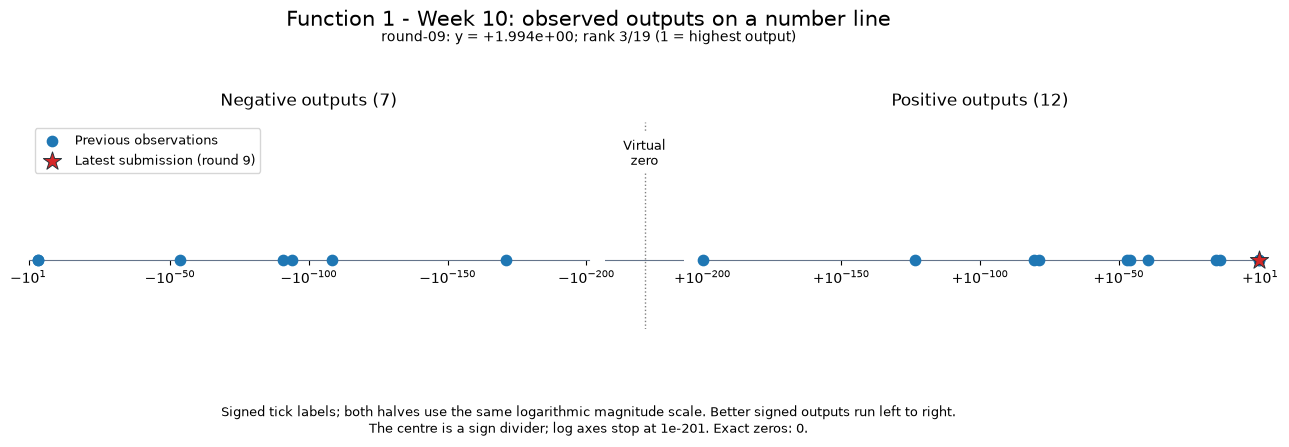

In [4]:
# Signed outputs on matching logarithmic magnitude scales.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

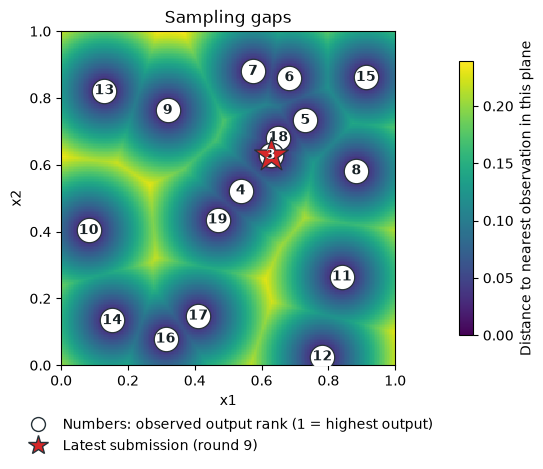

In [5]:
# Measured ranks and sampling gaps in the two-input square.
plot_sampling_gaps(
    review["plot_data"], pair=INPUT_COLUMNS,
    highlight=review["latest_mask"],
    highlight_label=f"Latest submission (round {review['latest_round']})",
    figsize=SAMPLING_GAP_SIZE, save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [6]:
# The terrain joins observed signed-log heights; it does not fit a model.
terrain_fig = plot_observed_terrain(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed-output terrain ({len(review['data'])} samples)",
    heights=signed_log(review["outputs"].to_numpy(), scale=TERRAIN_SCALE),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
        tickvals=signed_log(TERRAIN_TICKS, scale=TERRAIN_SCALE),
        ticktext=[f"{value:.0e}" if value else "0" for value in TERRAIN_TICKS]),
    height_description="signed-log heights", save_to=FIGURES_DIR / "observed-output-terrain.html",
    **TERRAIN_SETTINGS,
)
terrain_fig.show(config={**PLOT_CONFIG, "responsive": TERRAIN_SETTINGS["width"] is None})

The following storyboard stops at completion of the Week 2–5 fixed plan. The rounds 6–9 queries appear in the current coverage and terrain views above.

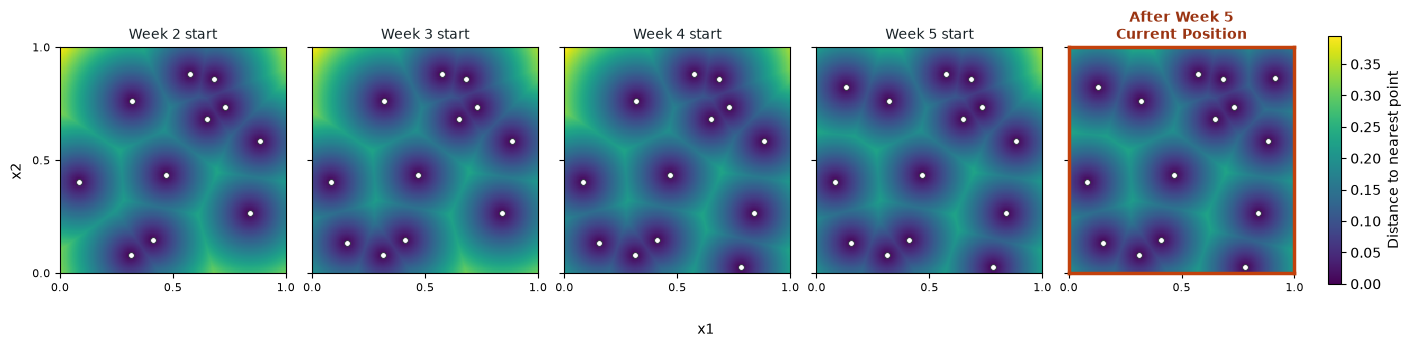

In [7]:
# Show the saved plan against recorded history; no optimisation is run here.
plot_fixed_exploration_progression(
    review["data"].loc[review["data"].source_round < 6], PLANNED_QUERIES, current_week=6,
    first_plan_week=FIRST_PLAN_WEEK,
    save_to=FIGURES_DIR / "fixed-exploration-progression.png",
)

In [8]:
# The completed shortlist returns an empty table; no next query is implied.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({
    column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS
}))

,x1,x2,Portal input
Week,,,


In [9]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

prepared = prepare_weekly_observation_review(review)

from observation_review_helpers import replay_weekly_forecast

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [10]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(formatter="{:.12g}", na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,7.7108751145e-16,Not applicable
Round 1,-0.00550934555381,7.7108751145e-16,-0.00550934555381
Round 2,-4.0577449722e-109,7.7108751145e-16,-7.7108751145e-16
Round 3,1.97281177559e-200,7.7108751145e-16,-7.7108751145e-16
Round 4,-9.54589035235e-172,7.7108751145e-16,-7.7108751145e-16
Round 5,-1.38635890998e-94,7.7108751145e-16,-7.7108751145e-16
Round 6,2.17091292512e-14,2.17091292512e-14,2.09380417398e-14
Round 7,1.99731436342,1.99731436342,1.99731436342
Round 8,1.99735569972,1.99735569972,4.13363024554e-05


### Replay the archived Week 9 fits at the submitted input

The exported weekly fits predate round 9. Evaluate them at the exact submitted coordinates. Some final choices used different decision models and broader peer evidence. GP latent SD describes modelled uncertainty about the latent score. Neural seed SD describes variation between the three training seeds.

In [11]:
# Replay the frozen Week 9 weekly fits at the actual submitted coordinates.
stage_dir = shared_dir.parent.parent
feedback = json.loads((stage_dir / "submissions/round-09-results.json").read_text(encoding="utf-8"))
submission_path = stage_dir / feedback["proposals_source"]
if (feedback["round"] != CURRENT_WEEK - 1
        or hashlib.sha256(submission_path.read_bytes()).hexdigest() != feedback["proposals_sha256"]):
    raise ValueError("Archived submission does not match the round result.")
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
result = feedback["results"][FUNCTION_NUMBER - 1]
portal_input = "-".join(f"{value:.6f}" for value in actual_point)
if (result["function"] != FUNCTION_NUMBER or not result["matches_proposal"]
        or result["point"] != actual_point.tolist() or result["output"] != actual_output
        or result["observations"] != len(review["data"])
        or portal_input != result["portal_input"]
        or portal_input != submission_path.read_text(encoding="utf-8").splitlines()[FUNCTION_NUMBER - 1]):
    raise ValueError("Official observation does not match the submitted and returned evaluation.")
previous_week = WEEK_DIR.parent / f"Week_{CURRENT_WEEK - 1:02d}"
previous_analysis = previous_week / "official" if ANALYSIS_DIR.name == "official" else previous_week
historical_forecast = replay_weekly_forecast(previous_analysis, function=FUNCTION_NUMBER,
    week=CURRENT_WEEK - 1, input_columns=INPUT_COLUMNS, point=actual_point)
scale = historical_forecast["height_scale"]
actual_target = float(signed_log(actual_output, scale=scale)) if scale is not None else actual_output
historical_forecast.update(
    source=(previous_analysis / "figures/neural-network-explorer.html").relative_to(stage_dir).as_posix(),
    portal_input=portal_input, actual_output=actual_output, actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast).drop(["official_snapshot_sha256", "explorer_sha256"]))


gp_model                                                       Gaussian process
data_scope                                         official_plus_retained_peers
prediction_units                                            signed-log height h
height_scale                                                                0.0
gp_mean                                                              198.163301
gp_latent_sd                                                           11.29366
neural_architecture                                                    relu-8-8
neural_mean                                                          130.822985
neural_seed_sd                                                        17.007168
source                        notebooks/Function_1/Week_09/official/figures/...
portal_input                                                  0.627434-0.628714
actual_output                                                          1.993993
actual_in_prediction_units              

### What the return adds

The tight local probe returned 1.993993185, about 0.00336 below the best. Three nearby positive returns support the local high-score region. The small differences leave the exact peak and its repeatability unresolved.

In [12]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 1,
  "week": 10,
  "observations": 19,
  "latest_id": "round-09",
  "latest_output": 1.9939931851536568,
  "latest_rank": 3,
  "rank_definition": "1 = highest output",
  "best_id": "round-08",
  "best_observed_output": 1.9973556997182018,
  "positive_outputs": 12,
  "negative_outputs": 7,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": -0.00550934555381189,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -0.005509345553812661
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": -4.0577449722040024e-109,
      "best_y": 7.710875114502849e-16,
      "change_vs_prior_best": -7.710875114502849e-16
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "r

### Course lifecycle for this review

1. **Define the goal and scope** — review round 9 for the project owner and prepare descriptive evidence for the Week 10 decision.
2. **Gather the data** — use the 25 November result, the independent official snapshot and the archived Week 9 weekly fits.
3. **Explore the data** — inspect measured ranks, progress and sampling coverage or full input profiles.
4. **Clean and preprocess the data** — validate finite values, dimensions, bounds and round counts at full precision.
5. **Select and engineer features** — keep the ordered input coordinates. Additional features are unnecessary for the measured views.
6. **Define the machine-learning task** — this review describes observations for a continuous black-box maximisation task.
7. **Partition the data** — not applicable to this descriptive review. The comparison uses fits already frozen before round 9.
8. **Select and train candidate methods** — not applicable to this review. The model notebook fits and compares the candidates.
9. **Evaluate and interpret the results** — compare the latest measured value with the incumbent, earlier outputs and the archived fits at the submitted coordinates.
10. **Deploy and iterate** — deployment is not applicable to this review. Carry the evidence into the next query decision.
